# 02 · Train MANet on all pets

Binary segmentation (pet vs background) on Oxford-IIIT Pet, cats **and** dogs.
Uses the full `MANet` from `manet_lib.py` (same blocks as the wildfire model: GroupNorm, PAB at the bottleneck, MFAB on every skip).
The best checkpoint by validation Dice is saved to `checkpoints/`.

In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch.utils.data import DataLoader

from manet_lib import (
    read_pet_list, split_train_val, PetSegDataset, build_model, count_params, MODELS,
    DiceBCELoss, run_epoch, predict_dataset, denormalize, overlay, mask_outline,
)

ROOT = Path("data/oxford-iiit-pet")
MODEL_NAME = "MANet"          # "MANet" | "MANet_small" | "MANet_small_small"
IMG_SIZE = 256
BATCH_SIZE = 16
NUM_WORKERS = 6
EPOCHS = 40
MAX_LR = 1e-3
WEIGHT_DECAY = 1e-4
PATIENCE = 10                 # early stop if val Dice doesn't improve for this many epochs
SEED = 42
CKPT_PATH = Path(f"checkpoints/{MODEL_NAME.lower()}_pets_best.pt")
HISTORY_PATH = Path(f"outputs/{MODEL_NAME.lower()}_history.csv")
CKPT_PATH.parent.mkdir(exist_ok=True); HISTORY_PATH.parent.mkdir(exist_ok=True)

torch.manual_seed(SEED); np.random.seed(SEED)
torch.backends.cudnn.benchmark = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")

Device: cuda NVIDIA GeForce RTX 5080 Laptop GPU


In [2]:
trainval = read_pet_list(ROOT, "trainval")
train_rows, val_rows = split_train_val(trainval, val_frac=0.15, seed=SEED)

train_ds = PetSegDataset(ROOT, train_rows, IMG_SIZE, train=True)
val_ds = PetSegDataset(ROOT, val_rows, IMG_SIZE, train=False)

loader_kw = dict(batch_size=BATCH_SIZE, num_workers=NUM_WORKERS, pin_memory=True, persistent_workers=NUM_WORKERS > 0)
train_loader = DataLoader(train_ds, shuffle=True, drop_last=True, **loader_kw)
val_loader = DataLoader(val_ds, shuffle=False, **loader_kw)
print(f"train={len(train_ds)} images ({len(train_loader)} batches)  val={len(val_ds)} images")

xb, yb, meta = next(iter(train_loader))
print("X:", tuple(xb.shape), xb.dtype, " Y:", tuple(yb.shape), yb.dtype)

train=3129 images (195 batches)  val=551 images


X: (16, 3, 256, 256) torch.float32  Y: (16, 1, 256, 256) torch.float32


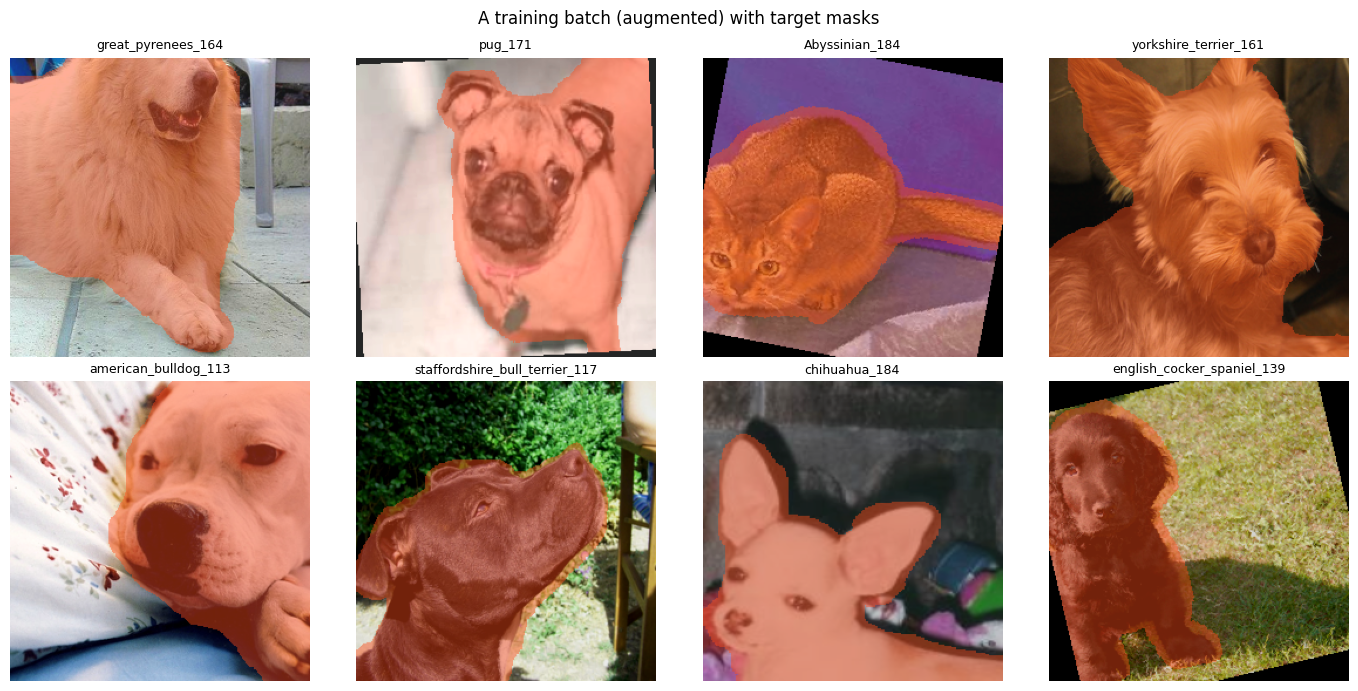

In [3]:
fig, axes = plt.subplots(2, 4, figsize=(14, 7))
for ax, x, y, name in zip(axes.flat, xb, yb, meta["name"]):
    ax.imshow(overlay(denormalize(x), y[0].numpy())); ax.set_title(name, fontsize=9); ax.axis("off")
fig.suptitle("A training batch (augmented) with target masks")
plt.tight_layout(); plt.show()

## Model size comparison

In [4]:
rows = []
for name, cls in MODELS.items():
    m = cls(n_channels=3, n_classes=1)
    rows.append({"model": name, "params (M)": round(count_params(m) / 1e6, 2)})
pd.DataFrame(rows)

,model,params (M)
0,MANet,33.40
1,MANet_small,8.29
2,MANet_small_small,2.07


In [5]:
model = build_model(MODEL_NAME, n_channels=3, n_classes=1).to(device)
criterion = DiceBCELoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=MAX_LR, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=MAX_LR, epochs=EPOCHS, steps_per_epoch=len(train_loader))

print(f"{MODEL_NAME}: {count_params(model):,} trainable params")
with torch.no_grad():
    print("Forward OK:", tuple(model(xb[:2].to(device)).shape))

MANet: 33,399,097 trainable params


Forward OK: (2, 1, 256, 256)


## Train

In [6]:
history = []
best_dice, best_epoch, bad_epochs = -1.0, -1, 0

for epoch in range(1, EPOCHS + 1):
    t0 = time.time()
    tr = run_epoch(model, train_loader, criterion, optimizer, scheduler, device=device)
    va = run_epoch(model, val_loader, criterion, device=device)
    history.append({"epoch": epoch, "lr": scheduler.get_last_lr()[0],
                    **{f"train_{k}": v for k, v in tr.items()}, **{f"val_{k}": v for k, v in va.items()}})

    improved = va["dice"] > best_dice + 1e-4
    if improved:
        best_dice, best_epoch, bad_epochs = va["dice"], epoch, 0
        torch.save({"model": model.state_dict(), "model_name": MODEL_NAME, "img_size": IMG_SIZE,
                    "epoch": epoch, "val_dice": best_dice}, CKPT_PATH)
    else:
        bad_epochs += 1

    print(f"epoch {epoch:03d} | {time.time() - t0:5.1f}s | "
          f"train loss {tr['loss']:.4f} dice {tr['dice']:.4f} | "
          f"val loss {va['loss']:.4f} dice {va['dice']:.4f} iou {va['iou']:.4f} acc {va['acc']:.4f}"
          + ("  *saved*" if improved else ""))

    if bad_epochs >= PATIENCE:
        print(f"Early stopping at epoch {epoch}.")
        break

pd.DataFrame(history).to_csv(HISTORY_PATH, index=False)
print(f"Best val Dice {best_dice:.4f} at epoch {best_epoch} -> {CKPT_PATH}")

epoch 001 |  92.9s | train loss 0.8854 dice 0.7397 | val loss 0.7651 dice 0.7611 iou 0.6306 acc 0.8039  *saved*


epoch 002 |  70.6s | train loss 0.7853 dice 0.7755 | val loss 0.8541 dice 0.7271 iou 0.5947 acc 0.7452


epoch 003 |  72.2s | train loss 0.7337 dice 0.7941 | val loss 0.7990 dice 0.7512 iou 0.6244 acc 0.7774


epoch 004 |  73.1s | train loss 0.7092 dice 0.8012 | val loss 0.6834 dice 0.7831 iou 0.6628 acc 0.8249  *saved*


epoch 005 |  72.8s | train loss 0.7095 dice 0.8003 | val loss 0.8364 dice 0.7352 iou 0.6058 acc 0.7518


epoch 006 |  73.8s | train loss 0.6540 dice 0.8187 | val loss 0.6647 dice 0.7989 iou 0.6838 acc 0.8394  *saved*


... (30 outputs left out)

epoch 037 |  73.0s | train loss 0.3215 dice 0.9113 | val loss 0.3467 dice 0.8909 iou 0.8167 acc 0.9186  *saved*


epoch 038 |  73.0s | train loss 0.3199 dice 0.9127 | val loss 0.3425 dice 0.8917 iou 0.8176 acc 0.9195  *saved*


epoch 039 |  72.8s | train loss 0.3189 dice 0.9132 | val loss 0.3445 dice 0.8914 iou 0.8173 acc 0.9187


epoch 040 |  72.7s | train loss 0.3208 dice 0.9119 | val loss 0.3432 dice 0.8917 iou 0.8176 acc 0.9191
Best val Dice 0.8917 at epoch 38 -> checkpoints\manet_pets_best.pt


## Training curves

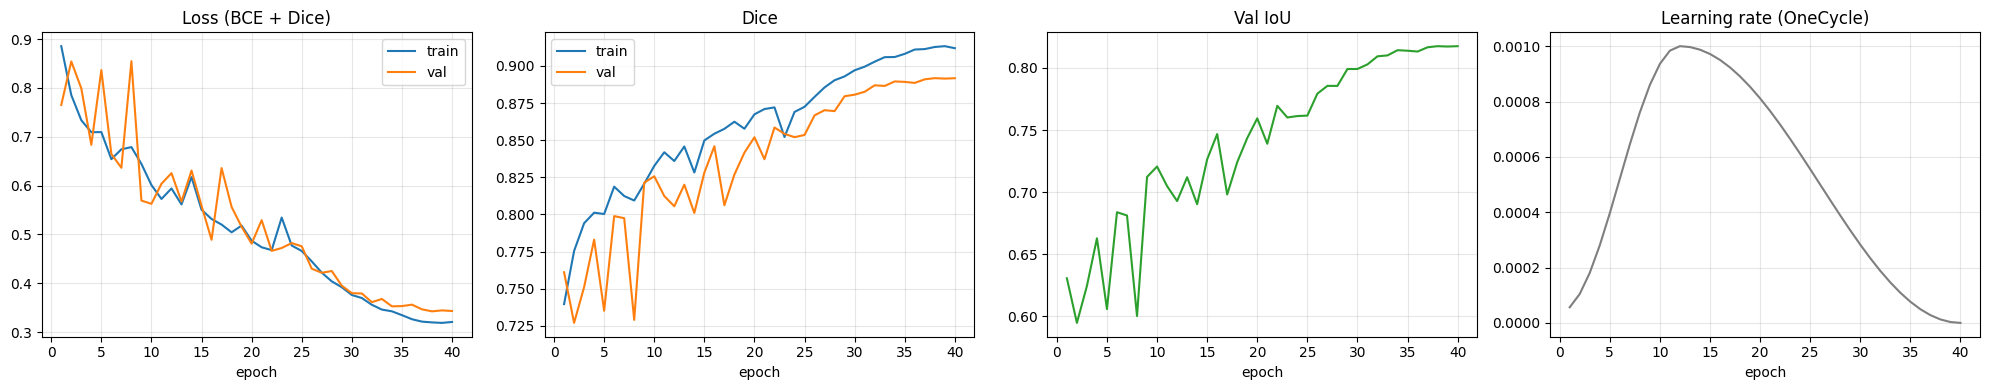

In [7]:
hist = pd.read_csv(HISTORY_PATH)
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].plot(hist.epoch, hist.train_loss, label="train"); axes[0].plot(hist.epoch, hist.val_loss, label="val")
axes[0].set_title("Loss (BCE + Dice)"); axes[0].legend()
axes[1].plot(hist.epoch, hist.train_dice, label="train"); axes[1].plot(hist.epoch, hist.val_dice, label="val")
axes[1].set_title("Dice"); axes[1].legend()
axes[2].plot(hist.epoch, hist.val_iou, color="tab:green"); axes[2].set_title("Val IoU")
axes[3].plot(hist.epoch, hist.lr, color="tab:gray"); axes[3].set_title("Learning rate (OneCycle)")
for a in axes: a.set_xlabel("epoch"); a.grid(alpha=0.3)
plt.tight_layout(); plt.savefig("outputs/02_training_curves.png", dpi=110); plt.show()

## Validation predictions from the best checkpoint

Loaded epoch 38 (val Dice 0.8917)


,dice,iou,acc
species,,,
cat,0.8856,0.8067,0.9038
dog,0.8946,0.8228,0.9269


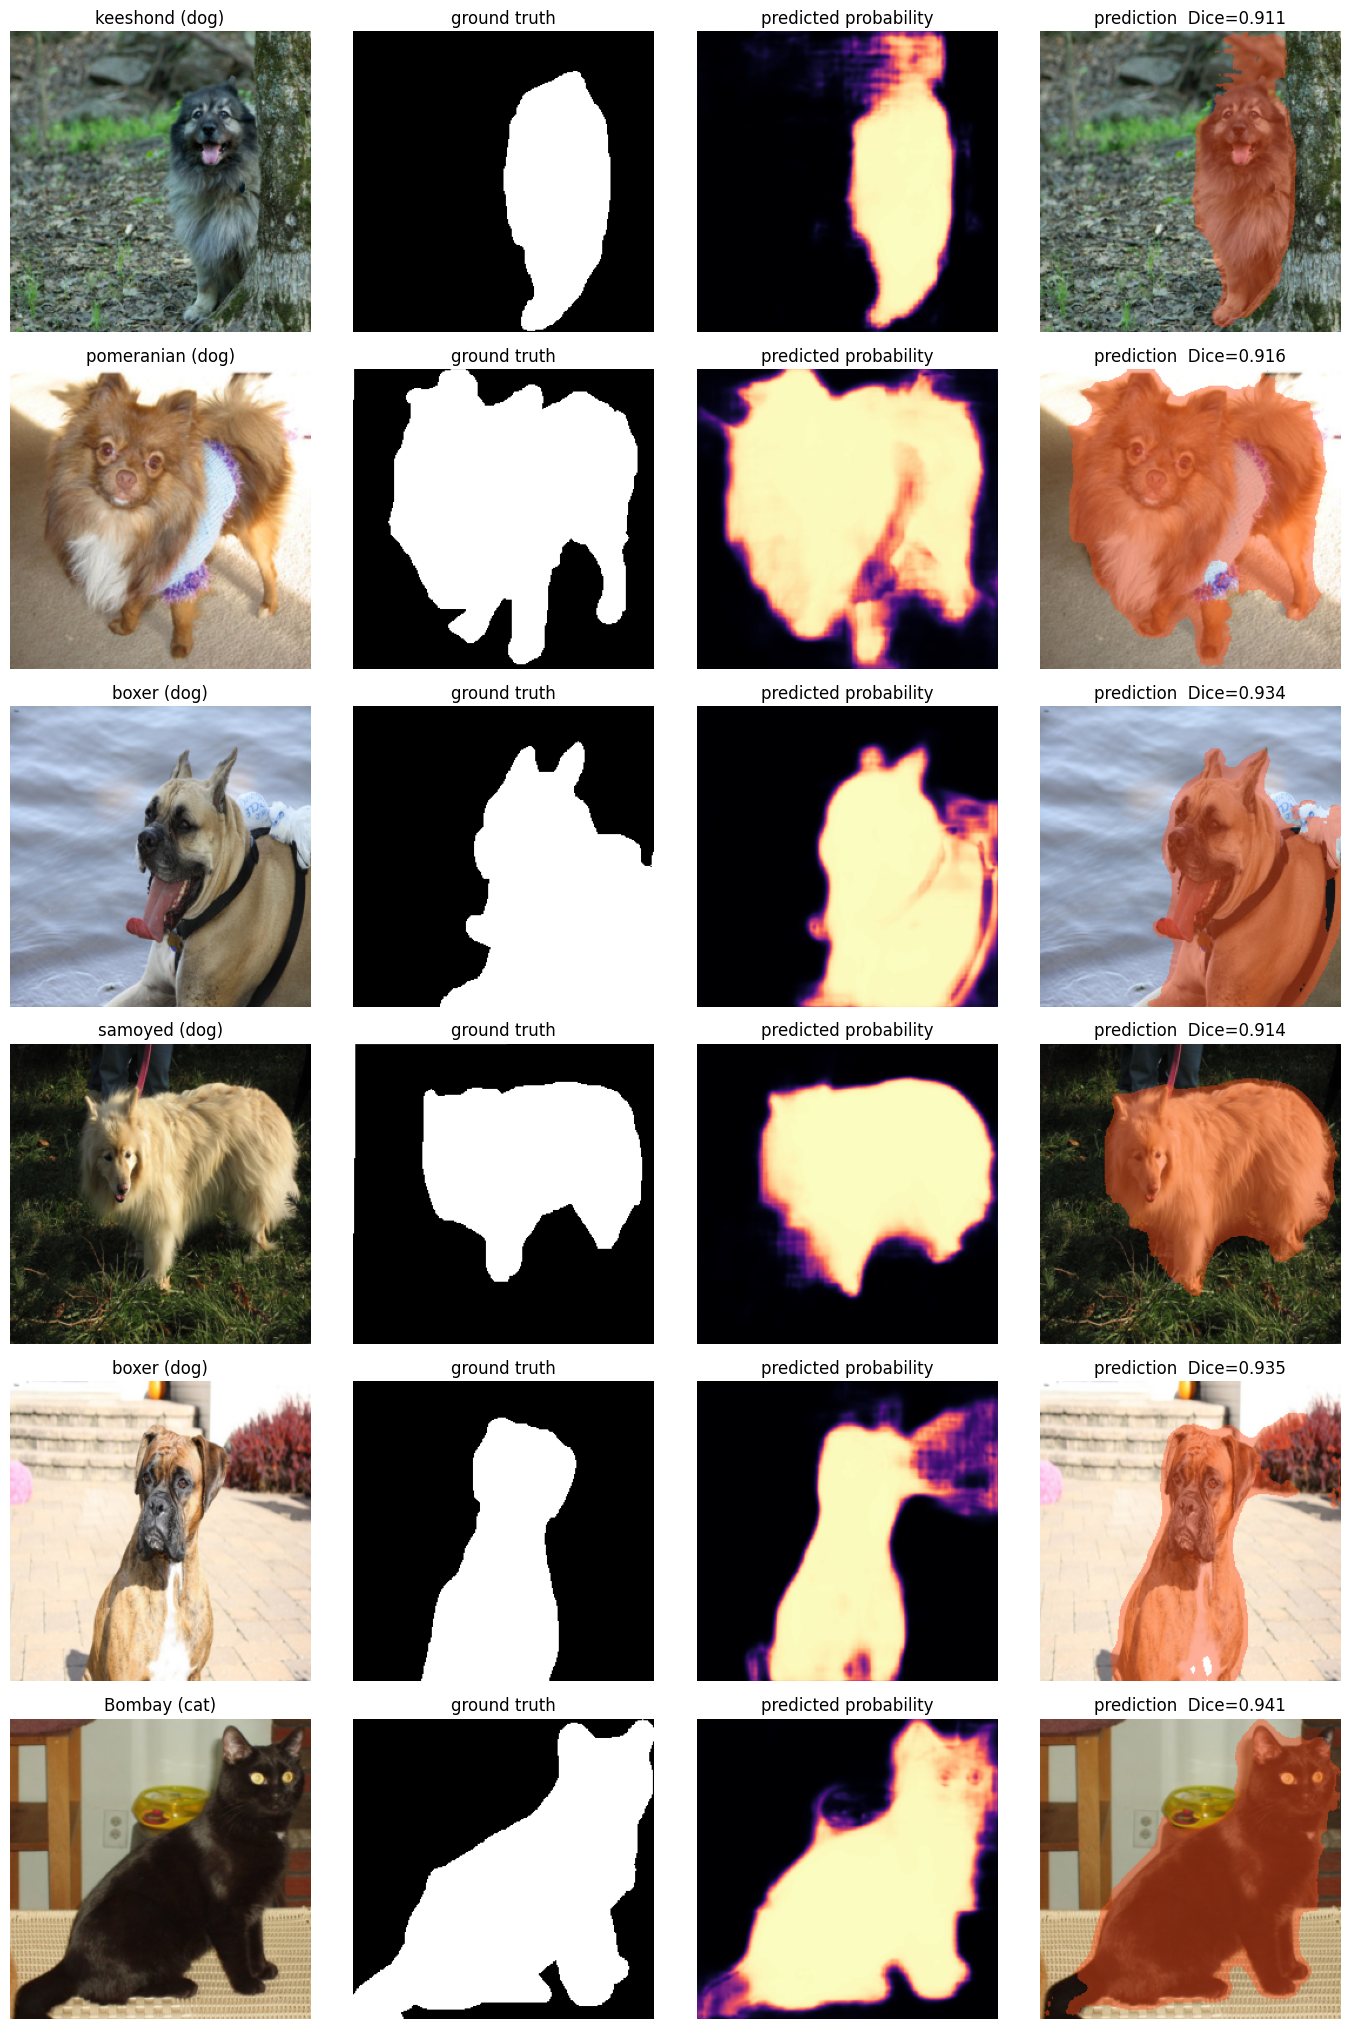

In [8]:
ckpt = torch.load(CKPT_PATH, map_location=device)
model.load_state_dict(ckpt["model"])
print(f"Loaded epoch {ckpt['epoch']} (val Dice {ckpt['val_dice']:.4f})")

val_records = predict_dataset(model, val_loader, device=device, keep_tensors=True)
val_df = pd.DataFrame([{k: v for k, v in r.items() if k in ("name", "species", "breed", "dice", "iou", "acc")} for r in val_records])
display(val_df.groupby("species")[["dice", "iou", "acc"]].mean().round(4))

rng = np.random.default_rng(SEED)
show = [val_records[i] for i in rng.choice(len(val_records), 6, replace=False)]
fig, axes = plt.subplots(len(show), 4, figsize=(14, 3.4 * len(show)))
for row, r in zip(axes, show):
    img = denormalize(r["image"])
    row[0].imshow(img); row[0].set_title(f"{r['breed']} ({r['species']})")
    row[1].imshow(r["mask"], cmap="gray"); row[1].set_title("ground truth")
    row[2].imshow(r["prob"], cmap="magma", vmin=0, vmax=1); row[2].set_title("predicted probability")
    row[3].imshow(overlay(img, r["pred"].numpy())); row[3].set_title(f"prediction  Dice={r['dice']:.3f}")
    for a in row: a.axis("off")
plt.tight_layout(); plt.show()